# 05 — Opportunity Sizing

**Question:** what is the model worth to a fab per year, and does it pay back its cost?

**Where the model sits.** WM-811K maps come from **wafer probe** (every die tested electrically at the end of the
line) — not WAT and not inline defect inspection. Most tool problems are caught earlier by **inline defect
inspection**, which stops the tool. The model adds value as a **second line of defence**:

1. **Escapes** — problems that inline inspection misses and that first show up at probe (e.g. CMP scratches,
   edge clusters, edge rings). The model shortens the lag between the probe result and someone acting on it.
2. **Review time** — engineers today review a sample of maps by hand; the model reads 100% of maps and sends only
   the uncertain ~2.9% to people.

It cannot shorten the time between the faulty process step and probe (often weeks) — only the
probe-to-action lag.

**Every number below is an assumption** except the model inputs, which come from the test set
(`04_evaluation.ipynb`). Edit the table and re-run to see the effect.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid")

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Model inputs (from the test set, not assumptions)

- **Share sent to engineers** at the 0.90 confidence cut-off: 993 of 34,585 test wafers = **2.9%**.
- **Recall on the escape types**: Scratch 0.745, Edge-Loc 0.901, Edge-Ring 0.988 → simple average **0.878**
  (escape types assumed equally common). This is lower than the overall 95.5% defect recall because Scratch is
  the model's weakest class.

In [2]:
TO_ENGINEER = 993 / 34_585
ESCAPE_RECALL = np.mean([0.745, 0.901, 0.988])   # Scratch, Edge-Loc, Edge-Ring (test-set recall)
print(f"Sent to engineers: {TO_ENGINEER:.1%} | recall on escape types: {ESCAPE_RECALL:.3f}")

Sent to engineers: 2.9% | recall on escape types: 0.878


## Assumptions

Sources: **user** = estimates from the project owner (fab experience); **Claude** = Claude's estimates where the
owner was unsure. Pessimistic / optimistic bound each input.

In [3]:
A = pd.DataFrame([
    # name,                          unit,          pessimistic, base,   optimistic, source
    ("wafers_per_month",             "wafers",       50_000,  50_000,  50_000, "user (UMC 12i-scale fab)"),
    ("share_reviewed_today",         "share",          0.05,    0.10,    0.20, "Claude"),
    ("minutes_per_review",           "minutes",           3,       5,       5, "user (5); Claude (3 low)"),
    ("engineer_cost_per_hour",       "USD/hour",         30,      45,      60, "user ($30); Claude (fully loaded)"),
    ("wafer_cost",                   "USD",           1_000,   1_250,   1_500, "user"),
    ("escapes_per_month",            "count",             2,     2.5,       3, "user (conservative)"),
    ("hours_to_act_today",           "hours",             8,      12,      24, "user"),
    ("hours_to_act_with_model",      "hours",             2,       1,       1, "Claude"),
    ("wafers_per_hour_on_tool",      "wafers/hour",      10,      20,      30, "Claude (fab moves ~69/h in total)"),
    ("share_lost_during_escape",     "share",          0.10,    0.30,    0.50, "Claude"),
    ("build_cost",                   "USD",         120_000,  75_000,  50_000, "Claude"),
    ("running_cost_per_year",        "USD/year",     40_000,  30_000,  20_000, "Claude"),
], columns=["input", "unit", "pessimistic", "base", "optimistic", "source"]).set_index("input")
A

,unit,pessimistic,base,optimistic,source
input,,,,,
wafers_per_month,wafers,50000.00,50000.0,50000.0,user (UMC 12i-scale fab)
share_reviewed_today,share,0.05,0.1,0.2,Claude
minutes_per_review,minutes,3.00,5.0,5.0,user (5); Claude (3 low)
engineer_cost_per_hour,USD/hour,30.00,45.0,60.0,user ($30); Claude (fully loaded)
wafer_cost,USD,1000.00,1250.0,1500.0,user
escapes_per_month,count,2.00,2.5,3.0,user (conservative)
hours_to_act_today,hours,8.00,12.0,24.0,user
hours_to_act_with_model,hours,2.00,1.0,1.0,Claude
wafers_per_hour_on_tool,wafers/hour,10.00,20.0,30.0,Claude (fab moves ~69/h in total)


## The calculation

- **Review saving / year** = wafers × (share reviewed today − share sent to engineers) × minutes ÷ 60 × hourly cost × 12
- **Escape saving / year** = escapes × (hours to act today − with model) × wafers per hour × share lost
  × wafer cost × recall on escape types × 12
- **Net value / year** = review + escape saving − running cost; **payback** = build cost ÷ monthly net value

In [4]:
def value(p):
    review = max(p["share_reviewed_today"] - TO_ENGINEER, 0) * p["wafers_per_month"] \
             * p["minutes_per_review"] / 60 * p["engineer_cost_per_hour"] * 12
    escape = p["escapes_per_month"] * (p["hours_to_act_today"] - p["hours_to_act_with_model"]) \
             * p["wafers_per_hour_on_tool"] * p["share_lost_during_escape"] * p["wafer_cost"] * ESCAPE_RECALL * 12
    net = review + escape - p["running_cost_per_year"]
    wafers_saved = escape / p["wafer_cost"]
    return {
        "review saving": review, "escape saving": escape, "total saving": review + escape,
        "running cost": p["running_cost_per_year"], "net value / year": net,
        "build cost": p["build_cost"],
        "payback (months)": p["build_cost"] / (net / 12) if net > 0 else np.inf,
        "wafers saved / year": wafers_saved,
    }

scenarios = pd.DataFrame({case: value(A[case]) for case in ["pessimistic", "base", "optimistic"]})
scenarios.to_csv(ROOT / "reports" / "opportunity_sizing.csv")
scenarios.style.format(lambda v: f"{v:,.1f}" if abs(v) < 100 else f"{v:,.0f}")

,pessimistic,base,optimistic
review saving,"19,159","160,398","513,864"
escape saving,"126,432","2,173,050","16,357,140"
total saving,"145,591","2,333,448","16,871,004"
running cost,"40,000","30,000","20,000"
net value / year,"105,591","2,303,448","16,851,004"
build cost,"120,000","75,000","50,000"
payback (months),13.6,0.4,0.0
wafers saved / year,126,"1,738","10,905"


## Which assumption moves the value most? (one at a time, others at base)

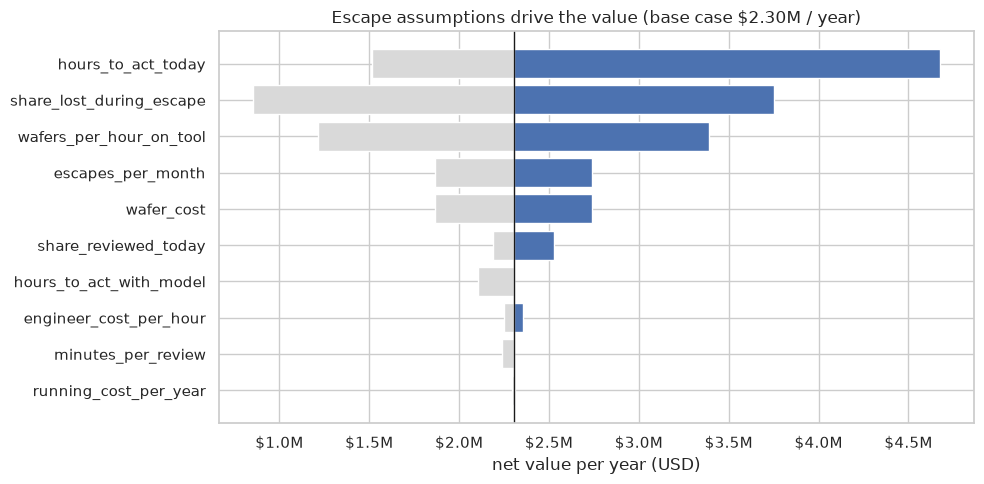

,input,pessimistic,optimistic,swing
5,hours_to_act_today,1513248.0,4674048.0,3160800.0
8,share_lost_during_escape,854748.0,3752148.0,2897400.0
7,wafers_per_hour_on_tool,1216923.0,3389973.0,2173050.0
3,wafer_cost,1868838.0,2738058.0,869220.0
4,escapes_per_month,1868838.0,2738058.0,869220.0
0,share_reviewed_today,2190948.0,2528448.0,337500.0
6,hours_to_act_with_model,2105898.0,2303448.0,197550.0
2,engineer_cost_per_hour,2249982.0,2356914.0,106932.0
1,minutes_per_review,2239289.0,2303448.0,64159.0
9,running_cost_per_year,2293448.0,2313448.0,20000.0


In [5]:
base_net = value(A["base"])["net value / year"]
rows = []
for name in A.index:
    lo, hi = A["base"].copy(), A["base"].copy()
    lo[name], hi[name] = A.at[name, "pessimistic"], A.at[name, "optimistic"]
    v_lo, v_hi = value(lo)["net value / year"], value(hi)["net value / year"]
    if v_lo != v_hi:
        rows.append({"input": name, "pessimistic": v_lo, "optimistic": v_hi, "swing": abs(v_hi - v_lo)})
tornado = pd.DataFrame(rows).sort_values("swing")

fig, ax = plt.subplots(figsize=(10, 5))
for i, r in enumerate(tornado.itertuples()):
    ax.barh(i, r.pessimistic - base_net, left=base_net, color="#d9d9d9")
    ax.barh(i, r.optimistic - base_net, left=base_net, color="#4c72b0")
ax.axvline(base_net, color="k", lw=1)
ax.set_yticks(range(len(tornado)), tornado["input"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v / 1e6:.1f}M"))
ax.set(xlabel="net value per year (USD)",
       title=f"Escape assumptions drive the value (base case ${base_net / 1e6:.2f}M / year)")
plt.tight_layout(); savefig("opportunity_tornado"); plt.show()
tornado.sort_values("swing", ascending=False).round(0)

## Break-even: how many escapes per month does the model need?

In [6]:
for case in ["pessimistic", "base"]:
    p = A[case].copy()
    per_escape = value({**p, "escapes_per_month": 1})["escape saving"]
    review = value({**p, "escapes_per_month": 0})["review saving"]
    breakeven = max(p["running_cost_per_year"] - review, 0) / per_escape
    print(f"{case:12s}: each escape caught is worth ${per_escape / 12:,.0f}; "
          f"break-even = {breakeven:.2f} escapes/month (covers running cost)")

pessimistic : each escape caught is worth $5,268; break-even = 0.33 escapes/month (covers running cost)
base        : each escape caught is worth $72,435; break-even = 0.00 escapes/month (covers running cost)


## Summary

| | Pessimistic | Base | Optimistic |
|---|---|---|---|
| Review time saved / year | $19k | $160k | $514k |
| Escape losses avoided / year | $126k | $2.17M | $16.4M |
| Net value / year (after running cost) | **$106k** | **$2.30M** | **$16.9M** |
| Payback of build cost | 14 months | under 2 weeks | days |
| Wafers saved / year | ~126 | ~1,740 | ~10,900 |

- **Escapes drive the value** (~93% in the base case): problems that inline inspection misses (CMP scratches,
  edge clusters, edge rings) and that first show up at probe. Review time saved is the smaller part.
- **Even the pessimistic case pays back** (~14 months). Break-even there is only ~0.33 escapes a month, far below
  the owner's conservative 2–3.
- **The biggest uncertainties** are hours-to-act today, share of wafers lost during an escape, and wafers per hour
  on the affected tool (tornado chart). These should be measured from the fab's excursion records in a pilot.
- **Scratch is the weakest class (74.5% recall)** and CMP scratches are a common escape — improving Scratch
  recall is the most valuable model upgrade.
- The model shortens only the **probe-to-action** lag, not the weeks between the faulty step and probe.
